In [5]:
!pip install -q ultralytics roboflow

In [6]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

In [7]:
user_secrets = UserSecretsClient()
api_key = user_secrets.get_secret("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=api_key)
project = rf.workspace("-97er7").project("road-damage-l1ju7-7amy1")
dataset = project.version(1).download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to road-damage-1 in yolov8:: 100%|██████████| 13519/13519 [00:03<00:00, 3907.41it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [8]:
import os, yaml

root = dataset.location
print("Location:", root)

with open(f"{root}/data.yaml") as f:
    cfg = yaml.safe_load(f)
print(cfg)

for split in ["train", "valid", "test"]:
    p = f"{root}/{split}/images"
    if os.path.exists(p):
        print(split, "->", len(os.listdir(p)), "images")

Location: /kaggle/working/road-damage-1
{'names': ['alligator', 'block', 'crack', 'edge', 'longitudinal', 'pothole', 'transverse'], 'nc': 7, 'roboflow': {'license': 'CC BY 4.0', 'project': 'road-damage-l1ju7-7amy1', 'url': 'https://universe.roboflow.com/-97er7/road-damage-l1ju7-7amy1/dataset/1', 'version': 1, 'workspace': '-97er7'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}
train -> 4930 images
valid -> 1146 images
test -> 681 images


In [9]:
import yaml

data_cfg = {
    "path": "/kaggle/working/road-damage-1",
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {i: n for i, n in enumerate(cfg["names"])},
}
with open("/kaggle/working/data.yaml", "w") as f:
    yaml.dump(data_cfg, f, sort_keys=False)

print(open("/kaggle/working/data.yaml").read())

path: /kaggle/working/road-damage-1
train: train/images
val: valid/images
test: test/images
names:
  0: alligator
  1: block
  2: crack
  3: edge
  4: longitudinal
  5: pothole
  6: transverse



class  alligator  block  crack  edge  longitudinal  pothole  transverse
split                                                                  
test         577     47     93     0           311      909          67
train       4337    305   1797    21          2008     6075         484
valid       1001     86    226     1           548     1600         126


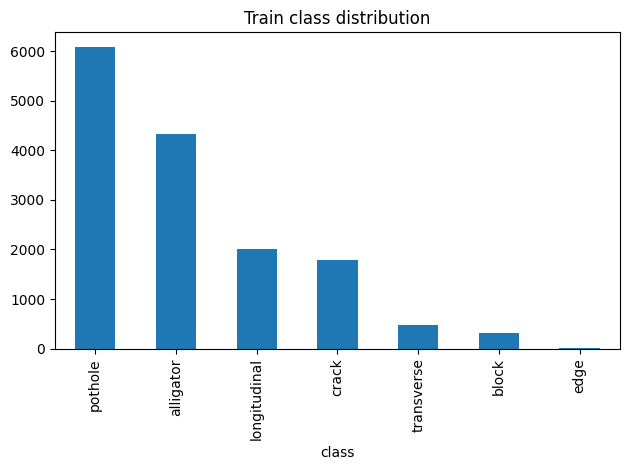

In [10]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

names = cfg["names"]
rows = []
for split in ["train", "valid", "test"]:
    for lf in glob.glob(f"{root}/{split}/labels/*.txt"):
        for line in open(lf):
            parts = line.split()
            if parts:
                rows.append((split, names[int(parts[0])]))

df = pd.DataFrame(rows, columns=["split", "class"])
print(df.groupby(["split", "class"]).size().unstack(fill_value=0))

df[df.split == "train"]["class"].value_counts().plot(kind="bar", title="Train class distribution")
plt.tight_layout()
plt.show()

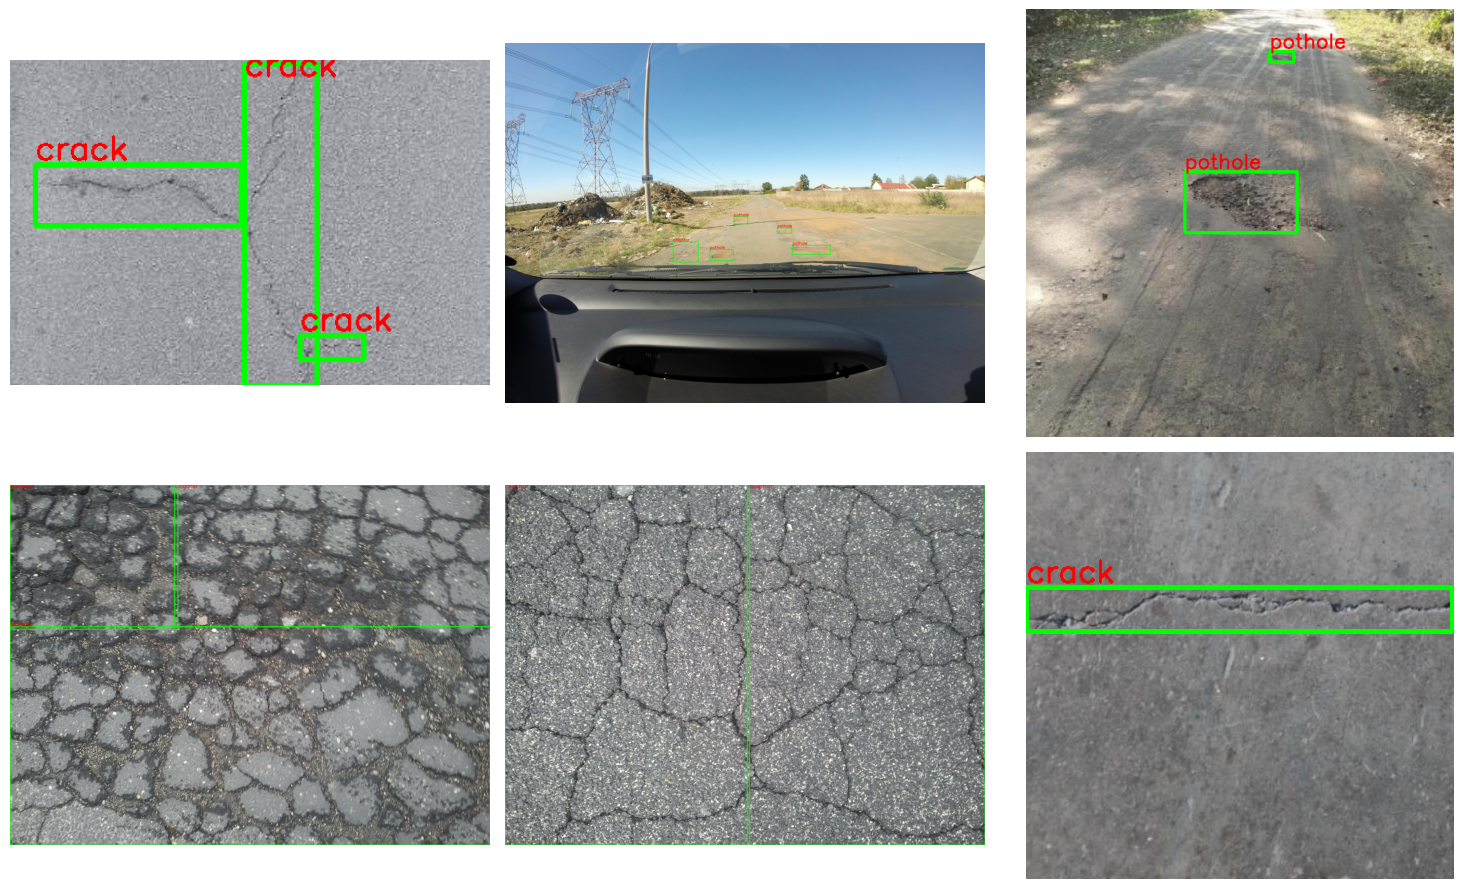

In [11]:
import random, cv2

imgs = random.sample(glob.glob(f"{root}/train/images/*"), 6)
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for ax, p in zip(axs.ravel(), imgs):
    im = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    lp = p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    if os.path.exists(lp):
        for line in open(lp):
            c, x, y, bw, bh = map(float, line.split()[:5])
            x1, y1 = int((x - bw/2) * w), int((y - bh/2) * h)
            x2, y2 = int((x + bw/2) * w), int((y + bh/2) * h)
            cv2.rectangle(im, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(im, names[int(c)], (x1, max(y1 - 5, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
    ax.imshow(im); ax.axis("off")
plt.tight_layout()
plt.show()

In [12]:
from ultralytics import YOLO
model = YOLO("yolov8n.pt")
model.train(data="/kaggle/working/data.yaml",epochs=3,imgsz=640,batch=16,workers=2,project="/kaggle/working/runs",name="smoke_test",)

Ultralytics 8.4.195 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_test, nbs=64, nms=None, opset=None, optimize=False, optimiz

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


        2/3      2.97G      2.072      2.677      1.985         55        640: 100% ━━━━━━━━━━━━ 308/308 5.5it/s 56.3s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.5it/s 10.2s0.2s
                   all       1142       3570      0.406      0.206      0.177     0.0925

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/3      2.97G      1.967      2.408      1.876         38        640: 100% ━━━━━━━━━━━━ 308/308 5.4it/s 57.1s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.6it/s 10.0s.2s
                   all       1142       3570       0.35      0.264      0.252      0.139

3 epochs completed in 0.057 hours.
Optimizer stripped from /kaggle/working/runs/smoke_test/weights/last.pt, 6.5MB
Optimizer stripped from /kaggle/working/runs/smoke_test/weights/best.pt, 6.5MB

Validating /kaggle/working/runs/smoke

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x780a3a124fc0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
  

In [13]:
model = YOLO("yolov8n.pt")
model.train(data="/kaggle/working/data.yaml",epochs=50,imgsz=640,batch=16,workers=2,optimizer="AdamW",lr0=0.001,seed=0,project="/kaggle/working/runs",name="v8n_base",)

Ultralytics 8.4.195 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v8n_base, nbs=64, nms=None, opset=None, optimize=False, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x780a97f01400>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
  

In [14]:
!cp -r /kaggle/working/runs /kaggle/working/runs_backup
!zip -r -q /kaggle/working/v8n_base.zip /kaggle/working/runs/v8n_base
!ls -lh /kaggle/working/v8n_base.zip

-rw-r--r-- 1 root root 19M Oct 31 20:30 /kaggle/working/v8n_base.zip


In [16]:
!ls /kaggle/working/runs/v8n_base
!ls /kaggle/working/runs/v8n_base/weights

args.yaml			 results.csv	       val_batch0_labels.jpg
BoxF1_curve.png			 results.png	       val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg      val_batch1_labels.jpg
BoxPR_curve.png			 train_batch12320.jpg  val_batch1_pred.jpg
BoxR_curve.png			 train_batch12321.jpg  val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch12322.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch1.jpg      weights
labels.jpg			 train_batch2.jpg
best.pt  last.pt


In [15]:
model = YOLO("yolo11n.pt")
model.train(data="/kaggle/working/data.yaml",epochs=50,imgsz=640,batch=16,workers=2,optimizer="AdamW",lr0=0.001,seed=0,project="/kaggle/working/runs",name="v11n_base",)

Ultralytics 8.4.195 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v11n_base, nbs=64, nms=None, opset=None, optimize=False, optimi

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x780a43bd1e10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
  

In [18]:
!zip -r -q /kaggle/working/v11n_base.zip /kaggle/working/runs/v11n_base

In [21]:
import time, glob, torch, pandas as pd
from ultralytics import YOLO

models = {
    "YOLOv8n": "/kaggle/working/runs/v8n_base/weights/best.pt",
    "YOLO11n": "/kaggle/working/runs/v11n_base/weights/best.pt",
}
imgs = sorted(glob.glob("/kaggle/working/road-damage-1/test/images/*"))[:200]

rows = []
for name, path in models.items():
    m = YOLO(path)
    r = m.val(data="/kaggle/working/data.yaml", split="test",
              imgsz=640, batch=16, plots=False, verbose=False)
    for _ in range(10):                      # warmup
        m.predict(imgs[0], imgsz=640, verbose=False)
    torch.cuda.synchronize(); t = time.time()
    for p in imgs:
        m.predict(p, imgsz=640, verbose=False)
    torch.cuda.synchronize()
    ms = (time.time() - t) / len(imgs) * 1000
    rows.append({
        "Model": name,
        "mAP50": round(r.box.map50, 3),
        "mAP50-95": round(r.box.map, 3),
        "Precision": round(r.box.mp, 3),
        "Recall": round(r.box.mr, 3),
        "ms/img": round(ms, 1),
        "FPS": round(1000 / ms, 1),
        "Size MB": round(__import__("os").path.getsize(path) / 1e6, 1),
    })
df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv("/kaggle/working/comparison_test.csv", index=False)

Ultralytics 8.4.195 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2541.3±1843.9 MB/s, size: 304.3 KB)
val: Scanning /kaggle/working/road-damage-1/test/labels.cache... 681 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 681/681 42.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 6.3it/s 6.8s0.1s
                   all        681       2004      0.555      0.574      0.576      0.352
Speed: 0.8ms preprocess, 3.4ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.195 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2840.9±2315.3 MB/s, size: 284.0 KB)
val: Scanning /kaggle/working/road-damage-1/test/la

In [22]:
!mkdir -p /kaggle/working/final_models
!cp /kaggle/working/runs/v8n_base/weights/best.pt /kaggle/working/final_models/v8n_best.pt
!cp /kaggle/working/runs/v11n_base/weights/best.pt /kaggle/working/final_models/v11n_best.pt
!cp /kaggle/working/runs/v8n_base/results.csv /kaggle/working/final_models/v8n_results.csv
!cp /kaggle/working/runs/v11n_base/results.csv /kaggle/working/final_models/v11n_results.csv
!cp /kaggle/working/data.yaml /kaggle/working/final_models/
!ls -lh /kaggle/working/final_models

total 12M
-rw-r--r-- 1 root root  193 Oct 31 21:45 data.yaml
-rw-r--r-- 1 root root 5.3M Oct 31 21:45 v11n_best.pt
-rw-r--r-- 1 root root 6.0K Oct 31 21:45 v11n_results.csv
-rw-r--r-- 1 root root 6.2M Oct 31 21:45 v8n_best.pt
-rw-r--r-- 1 root root 6.0K Oct 31 21:45 v8n_results.csv


2nd day

In [3]:
!pip install -q ultralytics roboflow
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow
api_key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=api_key)
project = rf.workspace("-97er7").project("road-damage-l1ju7-7amy1")
dataset = project.version(1).download("yolov8")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to road-damage-1 in yolov8:: 100%|██████████| 13519/13519 [00:03<00:00, 3749.76it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [11]:
import yaml
names = ['alligator','block','crack','edge','longitudinal','pothole','transverse']
cfg = {"path": "/kaggle/working/road-damage-1", "train": "train/images",
       "val": "valid/images", "test": "test/images",
       "names": {i: n for i, n in enumerate(names)}}
yaml.dump(cfg, open("/kaggle/working/data.yaml", "w"), sort_keys=False)

In [12]:
from ultralytics import YOLO

Tune 1


In [13]:
model = YOLO("yolo11n.pt")
model.train(data="/kaggle/working/data.yaml",epochs=50,imgsz=640,batch=16,workers=2,optimizer="SGD",lr0=0.01,seed=0,project="/kaggle/working/runs",name="v11n_sgd",)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v11n_sgd, nbs=64, nms=None, opset=None, optimize=False, optimize

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      3.54G       1.87      2.355      1.773         78        640: 100% ━━━━━━━━━━━━ 308/308 5.5it/s 56.5s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.7it/s 9.8s0.2s
                   all       1142       3570      0.325      0.107     0.0872     0.0356

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      3.54G       1.96      2.435      1.832         93        640: 100% ━━━━━━━━━━━━ 308/308 5.4it/s 56.6s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.7it/s 9.6s0.2s
                   all       1142       3570      0.431      0.149      0.117     0.0561

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      3.54G      2.007       2.52      1.869         60        640: 100% ━━━━━━━━━━━━ 308/308 5.5it/s 56.0s0.1ss
                 Class     Ima

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c0657fab8c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
  

Tune 2

In [15]:
model = YOLO("yolo11n.pt")
model.train(data="/kaggle/working/data.yaml",epochs=50,imgsz=800,batch=16,workers=2,optimizer="AdamW",lr0=0.001,seed=0,project="/kaggle/working/runs",name="v11n_img800",)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v11n_img800-2, nbs=64, nms=None, opset=None, optimize=False, op

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c05c9553000>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
  

In [18]:
!cp /kaggle/working/runs/v11n_img800-2/weights/best.pt /kaggle/working/v11n_img800_best.pt
!cp /kaggle/working/runs/v11n_sgd/weights/best.pt /kaggle/working/v11n_sgd_best.pt
!ls -lh /kaggle/working/*.pt

-rw-r--r-- 1 root root 5.3M Nov  1 15:04 /kaggle/working/v11n_img800_best.pt
-rw-r--r-- 1 root root 5.3M Nov  1 15:04 /kaggle/working/v11n_sgd_best.pt
-rw-r--r-- 1 root root 5.4M Nov  1 12:53 /kaggle/working/yolo11n.pt


In [6]:
!pip install -q ultralytics

In [11]:
!pip install -q roboflow
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow
api_key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=api_key)
project = rf.workspace("-97er7").project("road-damage-l1ju7-7amy1")
dataset = project.version(1).download("yolov8")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to road-damage-1 in yolov8:: 100%|██████████| 13519/13519 [00:03<00:00, 3787.02it/s]


In [13]:
import yaml
names = ['alligator','block','crack','edge','longitudinal','pothole','transverse']
cfg = {"path": "/kaggle/working/road-damage-1", "train": "train/images",
       "val": "valid/images", "test": "test/images",
       "names": {i: n for i, n in enumerate(names)}}
yaml.dump(cfg, open("/kaggle/working/data.yaml", "w"), sort_keys=False)

In [16]:
import time, glob, os, torch, pandas as pd
from ultralytics import YOLO

base = "/kaggle/input/datasets/razan3ssam/road-models"
models = {
    "YOLOv8n base":   (f"{base}/v8n_best.pt", 640),
    "YOLO11n base":   (f"{base}/v11n_best.pt", 640),
    "YOLO11n SGD":    (f"{base}/v11n_sgd_best.pt", 640),
    "YOLO11n img800": (f"{base}/v11n_img800_best.pt", 800),
}
imgs = sorted(glob.glob("/kaggle/working/road-damage-1/test/images/*"))[:200]

rows = []
for name, (path, sz) in models.items():
    m = YOLO(path)
    r = m.val(data="/kaggle/working/data.yaml", split="test",
              imgsz=sz, batch=16, plots=False, verbose=False)
    for _ in range(10):
        m.predict(imgs[0], imgsz=sz, verbose=False)
    torch.cuda.synchronize(); t = time.time()
    for p in imgs:
        m.predict(p, imgsz=sz, verbose=False)
    torch.cuda.synchronize()
    ms = (time.time() - t) / len(imgs) * 1000
    rows.append({
        "Model": name,
        "mAP50": round(r.box.map50, 3),
        "mAP50-95": round(r.box.map, 3),
        "Precision": round(r.box.mp, 3),
        "Recall": round(r.box.mr, 3),
        "ms/img": round(ms, 1),
        "FPS": round(1000 / ms, 1),
        "Size MB": round(os.path.getsize(path) / 1e6, 1),
    })
df = pd.DataFrame(rows)
print(df.to_string(index=False))
df.to_csv("/kaggle/working/comparison_final.csv", index=False)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4716.8±2964.4 MB/s, size: 677.5 KB)
val: Scanning /kaggle/working/road-damage-1/test/labels.cache... 681 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 681/681 136.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 6.8it/s 6.4s0.1s
                   all        681       2004      0.555      0.574      0.576      0.352
Speed: 0.7ms preprocess, 3.3ms inference, 0.0ms loss, 1.0ms postprocess per image
Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2668.7±1708.3 MB/s, size: 212.0 KB)
val: Scanning /kaggle/working/road-damage-1/test/l